# Model size analysis
Showcase of an abalation experiments to study the effect of model size

## 0 - Setup

In [1]:
%load_ext autoreload
%autoreload 2

import torch
import numpy as np
import matplotlib
matplotlib.rcParams['figure.dpi'] = 120

import sys
import os

# Adds the parent directory (root of your project) to the python path
sys.path.append(os.path.abspath(os.path.join('..')))

from src.models  import MerlinHeatQPINN, ClassicalHeatQPINN, MerlinTunableSimple
from src.pde     import HeatEquation
from src.loss    import total_loss
from src.train   import train
from src.eval    import evaluate
from src.plotter import (
    plot_training_history,
    plot_solution_comparison,
    plot_power_spectrum,
    plot_mode_l2_errors,
    plot_frequency_sweep,
    plot_multi_model_l2_error
)
from src.utils import quantum_outputsize_for_param_match, hilbert_space_dimension
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype  = torch.float32
print(f'device: {device}  |  dtype: {dtype}')

device: cpu  |  dtype: torch.float32


## 1 - Frequency Sweep
Train both models on heat equatin over a range of IC frequencies

In [41]:
FEATURE_SIZES_guess = [1, 2, 3, 4, 5, 6]#[2,4,8,16]
SEEDS = [42, 666, 69, 67, 13]
FREQUENCY = 3.5

In [42]:
%reload_ext autoreload
print(quantum_outputsize_for_param_match(4,4))
print(hilbert_space_dimension(4))
Frange = np.linspace(1,100,100)
Hrange = np.linspace(1,100,100)
outers = []
for i in Frange:
    for j in range(len(Hrange)):
        qo = quantum_outputsize_for_param_match(i,Hrange[j]) #len(Hrange)-j-1
        if int(qo)==qo:
            outers.append([int(i),int(Hrange[j])])

print(np.sort(outers,axis=1))

HIDDEN_READOUT = []
FEATURE_SIZES = []
for fs in FEATURE_SIZES_guess:
    for out_pair in outers:
        if out_pair[0]==fs:
            FEATURE_SIZES.append(fs)
            HIDDEN_READOUT.append(out_pair[1])
            break
print(FEATURE_SIZES)
print(HIDDEN_READOUT)
            

20.0
35
[[  1   1]
 [  1   2]
 [  1   3]
 ...
 [ 98 100]
 [ 99 100]
 [100 100]]
[1, 2, 3, 4, 5, 6]
[1, 3, 4, 4, 6, 2]


In [43]:
%reload_ext autoreload
sweep_results = {"classical": [], "qpinn_weights": []} #"qpinn": [], 
for j in range(len(FEATURE_SIZES)):
    feature_size = FEATURE_SIZES[j]
    hidden_readout = HIDDEN_READOUT[j]
    quantum_output_size = int(quantum_outputsize_for_param_match(feature_size,hidden_readout))

    pde = HeatEquation(freq=FREQUENCY)
    print(f"\n{'='*60}\nfreq = {FREQUENCY}")
    seed_results = {"classical": [], "qpinn_weights": []}
    for i,seed in enumerate(SEEDS):
#        # --- QPINN ---
#        qpinn = MerlinHeatQPINN().to(device)
#        train(model=qpinn, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
#        metrics, _, _, _, _ = evaluate(model=qpinn, pde=pde, device=device, dtype=dtype)
#        sweep_results["qpinn"].append({"frequency": freq, "rel_l2": metrics["rel_l2"]})
#        print(f"  QPINN_SEED_{seed}      rel_l2 = {metrics['rel_l2']:.4e}")

        # --- QPINN WEIGHTS ---
        qpinn_weights = MerlinTunableSimple(feature_size=feature_size, hidden_readout=hidden_readout).to(device)
        train(model=qpinn_weights, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
        metrics, _, _, _, _ = evaluate(model=qpinn_weights, pde=pde, device=device, dtype=dtype)
        seed_results["qpinn_weights"].append(metrics["rel_l2"])

        print(f"  QPINN WEIGHTS_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

        total_params = sum(p.numel() for p in qpinn_weights.parameters())
        trainable_params = sum(p.numel() for p in qpinn_weights.parameters() if p.requires_grad)
        #print(f"Parameters — total: {total_params:,}  trainable: {trainable_params:,}")
        qpinn_num_weights = sum(p.numel() for p in qpinn_weights.parameters() if p.requires_grad)
        


        # --- Classical ---
        classical = ClassicalHeatQPINN(feature_size=feature_size, quantum_output_size=quantum_output_size, hidden_readout=hidden_readout).to(device)
        train(model=classical, pde=pde, loss_fn=total_loss, log_every=100, seed=seed)
        metrics, _, _, _, _ = evaluate(model=classical, pde=pde, device=device, dtype=dtype)
        seed_results["classical"].append(metrics["rel_l2"])
        
        print(f"  Classical_SEED_{seed}   rel_l2 = {metrics['rel_l2']:.4e}")

        total_params = sum(p.numel() for p in classical.parameters())
        trainable_params = sum(p.numel() for p in classical.parameters() if p.requires_grad)
        #print(f"Parameters — total: {total_params:,}  trainable: {trainable_params:,}")
        classical_num_weights = sum(p.numel() for p in classical.parameters() if p.requires_grad)

    
    sweep_results["classical"].append({"frequency": classical_num_weights, "rel_l2": seed_results["classical"]})
    sweep_results["qpinn_weights"].append({"frequency": qpinn_num_weights, "rel_l2": seed_results["qpinn_weights"]})



freq = 3.5
Parameters — total: 76  trainable: 76

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 5.1373e+00 | PDE: 1.20e-05 | Cons: 9.95e-02 | IC: 5.12e-01 | BC: 4.98e-03 | Time: 0.0s
Epoch   100/300 | Loss: 5.3222e+00 | PDE: 6.18e-04 | Cons: 2.88e-05 | IC: 5.31e-01 | BC: 6.82e-03 | Time: 0.6s
Epoch   200/300 | Loss: 5.1408e+00 | PDE: 1.44e-03 | Cons: 3.75e-05 | IC: 5.13e-01 | BC: 8.36e-03 | Time: 1.2s
Epoch   300/300 | Loss: 4.7719e+00 | PDE: 2.38e-03 | Cons: 7.21e-05 | IC: 4.76e-01 | BC: 5.66e-03 | Time: 1.8s

Done — 1.8s total
Evaluating on 60×60 grid …
  Relative L2 : 1.0286e+00
  MAE         : 8.6687e-02
  Max abs err : 1.0630e+00
  RMSE        : 1.6057e-01
  QPINN WEIGHTS_SEED_42   rel_l2 = 1.0286e+00
Parameters — total: 76  trainable: 76

Training for 300 epochs on cpu  (dtype=torch.float32)
Epoch     1/300 | Loss: 6.3426e+00 | PDE: 1.05e-03 | Cons: 1.13e-01 | IC: 5.51e-01 | BC: 8.19e-01 | Time: 0.0s
Epoch   100/300 | Loss: 5.3191e+00 | PDE: 3.47e

Saved: figures/fourier_demo/weights_sweep_freq=3.5.png


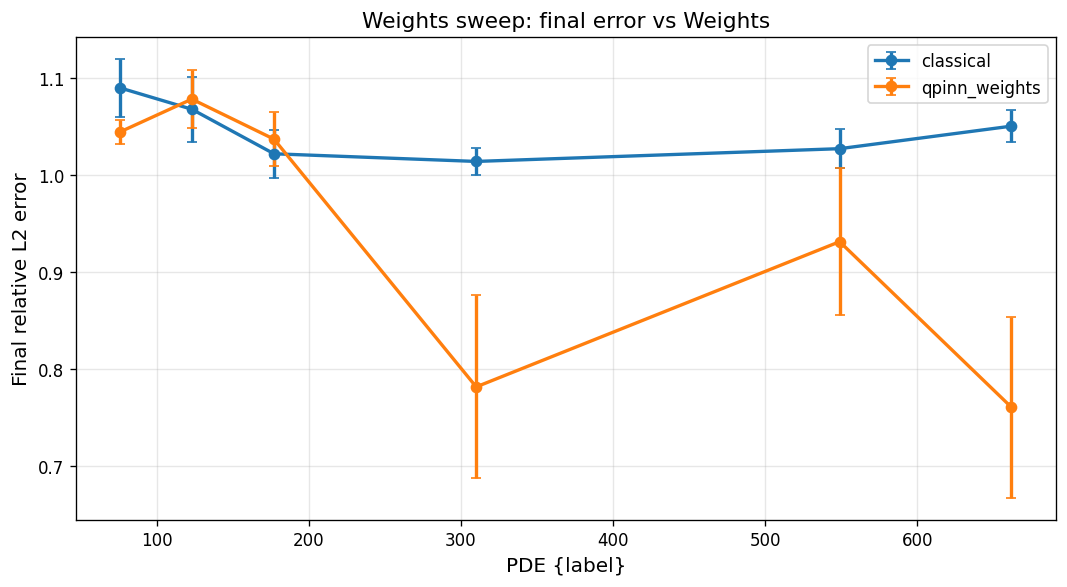

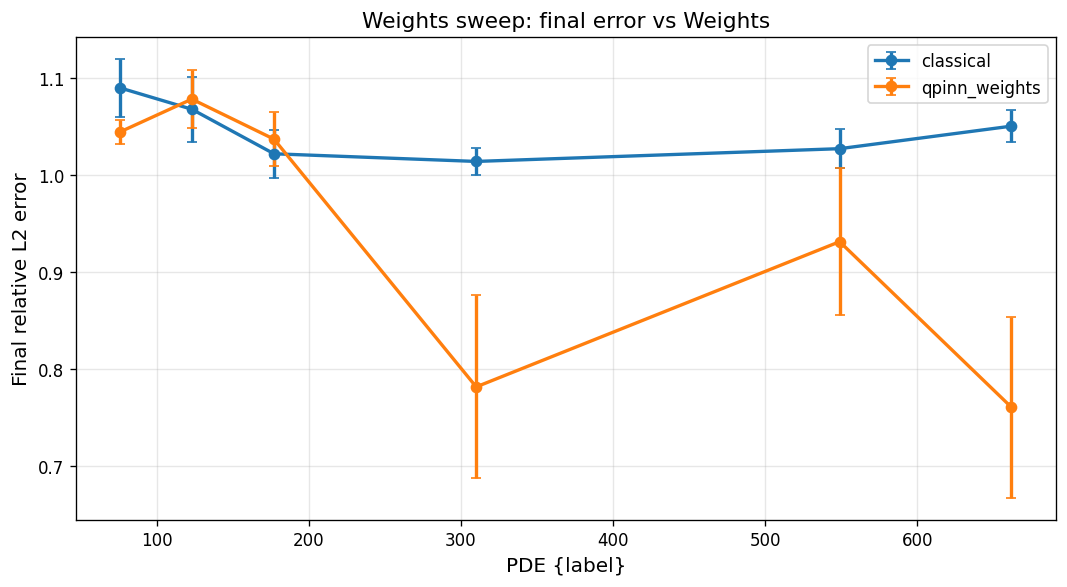

In [44]:
%reload_ext autoreload

plot_frequency_sweep(
    sweep_results,
    save_path = "figures/fourier_demo/weights_sweep_freq=3.5.png",
    show      = True,
    label     = 'Weights',
)

## 2 - Train both models with same frequency and compare

In [ ]:
FREQUENCY = 3.0

In [ ]:

ref_pde = HeatEquation(freq=FREQUENCY)

# QPINN
qpinn_ref = MerlinHeatQPINN().to(device)
history_q = train(model=qpinn_ref, pde=ref_pde, epochs = 600)

# Classical
classical_ref = ClassicalHeatQPINN().to(device)
history_c = train(model=classical_ref, pde=ref_pde, epochs = 600)

qpinn_weights_ref = MerlinTunableSimple().to(device)
history_qpinn_weights = train(model=qpinn_weights_ref, pde=ref_pde, epochs = 600)

In [ ]:
# Evaluate models
grid_n = 60


_, U_pred_q, U_true, x_grid, t_grid = evaluate(model=qpinn_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_c, _,      _,      _      = evaluate(model=classical_ref, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

_, U_pred_q_w, _,      _,      _      = evaluate(model=qpinn_weights, pde=ref_pde,
                                                device=device, dtype=dtype, nx=grid_n, nt=grid_n)

#TODO : figure out here Q error is smaller than C error ??? this doesnt match results from other pipeline

In [ ]:
plot_solution_comparison(U_pred_q,U_true)
plot_solution_comparison(U_pred_c,U_true)
plot_solution_comparison(U_pred_q_w,U_true)


### 2.1 - Compare power spectra

In [ ]:
print("QPINN power spectrum")
plot_power_spectrum(U_pred_q, U_true, save_path="../figures/demo_fourier/power_spectrum_q.png", exclude_0_mode=False)

print("Classical power spectrum")
plot_power_spectrum(U_pred_c, U_true, save_path="../figures/demo_fourier/power_spectrum_c.png", exclude_0_mode=False)

### 2.2 Compare per-mode L2 error

In [ ]:
print("QPINN mode errors")
plot_mode_l2_errors(U_pred_q, U_true,
                    save_path="figures/fourier_demo/l2_error_Q.png")

print("Classical mode errors")
plot_mode_l2_errors(U_pred_c, U_true,
                    save_path="figures/fourier_demo/l2_error_C.png")

## Compare directly

In [ ]:


plot_multi_model_l2_error(U_true, [U_pred_q, U_pred_c],["Qpinn", "C PINN"])